# Figure 5: Sensitivity Analysis for Projected Discharge


In [1]:
file ='../Figures'

import pandas as pd
import numpy as np

import os

# function that creates dataframe from list of files in a path
def create_dataframe(path, tag):
# get all files in the path
    files = os.listdir(path)

    # create a dictionary to store all dataframes
    dfs = {}

    for file in files:
        if file.endswith('.csv'):
            # read the csv file
            df = pd.read_csv(path+file)

            # if file includes tag in name
            if tag in file:
                # create string with only the characters before "_summary.csv"
                mult = file.split('_summary.csv')[0]
                mult = mult.split(tag)[1]
                # save the dataframe in the dictionary
                dfs[mult] = df
    
    return dfs

# function that creates a dataframe with the data of a specific WWTP
def create_df(WWTP, dfs):
    df = pd.DataFrame(index=sorted(dfs.keys()))
    for key in sorted(dfs.keys()):
        df_small = dfs[key].loc[dfs[key]['Abbreviation'] == WWTP]
        for column in df_small.columns:
            # add the value to Palo_Alto data with the column being the key and the row is the column name
            df.loc[key, column] = df_small[column].values[0]
    return df

# function that creates a dataframe for total values
def create_df_total(dfs):
    df = pd.DataFrame(index=sorted(dfs.keys()))
    for key in sorted(dfs.keys()):
        df_small = dfs[key].loc[dfs[key]['Abbreviation'] == 'Total']
        for column in df_small.columns:
            df.loc[key, column] = df_small[column].values[0]
    return df

## Plot sensitivity analysis of total cost 

In [2]:
# plot total cost of the three different dataframes as a function of the key
import matplotlib.pyplot as plt

def plot_total_cost(WWTPs, dfs, title):
    colors = ['green', 'red', 'purple', 'black', 'yellow', 'pink', 'brown', 'grey']
    hfont = {'fontname':'Helvetica', 'size':12}
    hfont_ticks = {'fontname':'Helvetica', 'size':10}

    fig,ax = plt.subplots(figsize=(10, 4))
    for i,WWTP in enumerate(WWTPs):
        df = create_df(WWTP, dfs)
        per = [float(ind)*100 - 100 for ind in df.index]
        ticks = [per[a] for a in range(0, len(per), 5)]
        #per = [str(round(float(ind)*100 - 100,4)) + '%' for ind in df.index]
        #ticks = [str(round(float(ind)*100 - 100)) + '%' for ind in df.index]
        plt.plot(per, df['Total_cost'], label=WWTP, marker='o', color=colors[i])
    
    total_cost = sum([create_df(WWTP, dfs)['Total_cost'] for WWTP in WWTPs])
    plt.plot(per, total_cost, label='Total', marker='x', color='black', linestyle='--')
    
    # add dashed vertical line at 0% variation
    #plt.axvline(x=0, color='black', linestyle='--')
        
    
    ax.set_xticks(ticks, [str(round(tick)) + '%' for tick in ticks], **hfont_ticks)
    ax.set_xlabel('Percent change in projected discharge for each WWTP', **hfont)

    # add a secondary x-axis
    df = create_df_total(dfs)
    
    secax = ax.secondary_xaxis('top')
    ticks_2 = [round(df.Total_removal[a]*10**-3) for a in range(0, len(per), 5)]
    secax.set_xticks(ticks, ticks_2, **hfont)
    secax.set_xlabel('TIN removed in the subembayment (1,000 lb N)', **hfont)


    plt.legend(prop = {'family':'Helvetica', 'size':10})
    plt.ylabel(title + ' total NPV cost ($million)', **hfont)
    plt.tight_layout()
    plt.show()
    
    return fig, ax

# plot individual costs
def plot_individual_costs (WWTPs, dfs, plot_tag):
    colors = ['green', 'red', 'purple', 'black', 'yellow', 'pink', 'brown', 'grey']
    hfont = {'fontname':'Helvetica', 'size':12}
    capex_col = ['SS_capex_NPV', 'L2_capex_NPV', 'L2upg3_capex_NPV', 'L3_capex_NPV']
    opex_col = ['SS_opex_NPV', 'L2_opex_NPV', 'L2upg3_opex_NPV', 'L3_opex_NPV']
    labels = ['SS', 'L2', 'L2upg3', 'L3']
    
    #create figure with 3 subplots
    fig, axs = plt.subplots(len(WWTPs), 1, figsize=(10, 10))
    for i,WWTP in enumerate(WWTPs):
        df = create_df(WWTP, dfs)
        per = [float(ind)*100 - 100 for ind in df.index]
        ticks = [per[a] for a in range(0, len(per), 5)]
        #per = [str(round(float(ind)*100 - 100,4)) + '%' for ind in df.index]

        for j,column in enumerate(capex_col):
            if plot_tag == 'total':
                value = df[capex_col[j]] + df[opex_col[j]] 
                axs[i].set_ylabel('Total NPV cost ($million)', **hfont)
            elif plot_tag == 'capex':
                value = df[capex_col[j]] 
                axs[i].set_ylabel('NPV Capex ($million)', **hfont)
            elif plot_tag == 'opex':
                value = df[opex_col[j]] 
                axs[i].set_ylabel('NPV Opex ($mil/yr)', **hfont)
            
            axs[i].plot(per, value, label=labels[j], marker='o', color=colors[j])
            axs[i].set_title(WWTP)
            axs[i].set_xticks(ticks, [str(round(tick)) + '%' for tick in ticks])
            axs[i].legend()
    
    plt.xlabel('Percent change in projected discharge for each WWTP', **hfont)
    
    plt.tight_layout()
    plt.show()
    
    return fig, axs

### Create dataframes for all cases 

In [3]:
path = '../Results/Sensitivity_all_coordination_S/'
WWTPS = ['Palo Alto', 'SJSC', 'Sunnyvale']

dfs_SNC = create_dataframe(path, 'No_coordination_')
dfs_SPC = create_dataframe(path, 'Partial_coordination_')
dfs_SFC = create_dataframe(path, 'Full_coordination_')
dfs_SFC_10_yr = create_dataframe(path, 'Full_10yr_coordination__')

In [4]:
path = '../Results/Sensitivity_all_coordination_NS/'
WWTPS = ['Palo Alto', 'SJSC', 'Sunnyvale']

dfs_NSNC = create_dataframe(path, 'No_coordination_')
dfs_NSPC = create_dataframe(path, 'Partial_coordination_')
dfs_NSFC = create_dataframe(path, 'Full_coordination_')

### Create daraframes for total costs of each case

In [5]:
df_total_SNC = create_df_total(dfs_SNC)
df_total_SPC = create_df_total(dfs_SPC)
df_total_SFC = create_df_total(dfs_SFC)
df_total_SFC_10 = create_df_total(dfs_SFC_10_yr)

In [6]:
df_total_NSNC = create_df_total(dfs_NSNC)
df_total_NSPC = create_df_total(dfs_NSPC)
df_total_NFC = create_df_total(dfs_NSFC)

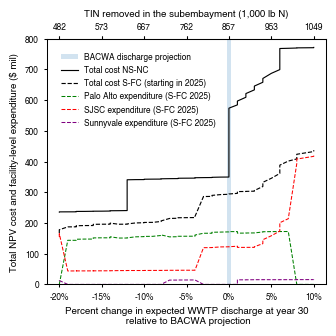

In [9]:

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


markers = ['o', 'd', 's']
labels = ['SS', 'L2', 'L2upg3', 'L3']
colors = ['green', 'red', 'purple', 'black', 'yellow', 'pink', 'brown', 'grey']
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2
m_size = 3.5
ling_fig_wid = 0.75

#create figure with 4 subplots
fig, axs = plt.subplots(1, 1, figsize=(88/25.4, 88/25.4))

# Plot total costs for SNC
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']

for i,WWTP in enumerate(WWTPs):
    df = create_df(WWTP, dfs_SFC)
    per = [round(float(ind)*100 - 100) for ind in df.index]
    ticks = [per[a] for a in range(0, len(per), 10)]

axs.axvspan(-0.25, 0.25, alpha=0.2, label = 'BACWA discharge projection')

total_cost_NSNC = sum([create_df(WWTP, dfs_NSNC)['Total_cost'] for WWTP in WWTPs])

axs.plot(per, total_cost_NSNC, label='Total cost NS-NC', color='black', linestyle='-', linewidth=ling_fig_wid*1.1, markersize=m_size)
'''
total_cost_NSPC = sum([create_df(WWTP, dfs_NSPC)['Total_cost'] for WWTP in WWTPs])
axs.plot(per, total_cost_NSPC, label='Total cost NS-PC', color='black', linestyle=':', linewidth=ling_fig_wid, markersize=m_size)
'''
total_cost_SPC = sum([create_df(WWTP, dfs_SPC)['Total_cost'] for WWTP in WWTPs])
#axs.plot(per, total_cost_SPC, label='Total cost S-PC', color='black', linestyle=':', linewidth=ling_fig_wid, markersize=m_size)

total_cost_SFC = sum([create_df(WWTP, dfs_SFC)['Total_cost'] for WWTP in WWTPs])
axs.plot(per, total_cost_SFC, label='Total cost S-FC (starting in 2025)', color='black', linestyle='--', linewidth=ling_fig_wid*1.1, markersize=m_size)


for i,WWTP in enumerate(WWTPs):
    df = create_df(WWTP, dfs_SFC)
    per = [round(float(ind)*100 - 100) for ind in df.index]
    ticks = [per[a] for a in range(0, len(per), 10)]
    axs.plot(per, df['Total_cost'].values, label=WWTP + ' expenditure (S-FC 2025)', color=colors[i], linestyle= '--', linewidth=ling_fig_wid, markersize=m_size)




## add a secondary x-axis
df = create_df_total(dfs_SFC)
secax = axs.secondary_xaxis('top')
ticks_2 = [round(df.Total_removal.iloc[a]*10**-3) for a in range(0, len(per), 10)]
secax.set_xticks(ticks, ticks_2, **hfont)
secax.set_xlabel('TIN removed in the subembayment (1,000 lb N)', **hfont)
axs.set_ylabel('S-NC Total Cost\n(NPV $mil)', **hfont)
axs.legend(prop = {'family':'Helvetica', 'size':leg_size}, loc='upper left', frameon=False, bbox_to_anchor=(0.025, 0.975), ncol = 1)


secax.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica', width=line_wid, length=bord_wid)
secax.spines["top"].set_linewidth(line_wid)




axs.xaxis.set_ticks_position('both')
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)


plt.ylim([0, 800])

plt.xticks(ticks, [str(round(tick)) + '%' for tick in ticks]) 
axs.set_xlabel('Percent change in expected WWTP discharge at year 30\n relative to BACWA projection', **hfont)
plt.ylabel('Total NPV cost and facility-level expenditure ($ mil)', **hfont)
axs.tick_params(axis="both", which='major', labelfontfamily= 'Helvetica', width=line_wid, length=bord_wid, labelsize=leg_size)


fig.tight_layout()
fig.savefig(file + "/Fig_4.svg", format="svg", dpi=300)

## Sensitivity plot of cost-optimal treatment construction vs varying discharge projections

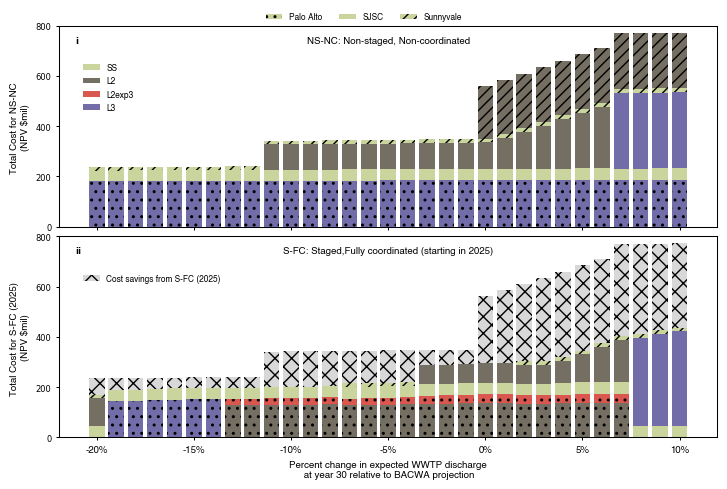

In [10]:
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']

colors = {'L3': '#726DA8', 'L2': '#746F62', 'SS': '#CAD49D', 'L2upg3': '#D9574F', 'total': '#EB5E28', 'required': '#8EA8C3'}
capex_col = ['SS_capex_NPV', 'L2_capex_NPV', 'L2upg3_capex_NPV', 'L3_capex_NPV']
opex_col = ['SS_opex_NPV', 'L2_opex_NPV', 'L2upg3_opex_NPV', 'L3_opex_NPV']
labels = ['SS', 'L2', 'L2upg3', 'L3']
hatch_style = ['..','','///']


desired_indices = df_total_SNC.index.tolist()[::2]


hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 7
leg_size = 6
line_wid = 0.75
bord_wid = 2
m_size = 2.5

#create figure with 4 subplots

fig, axs = plt.subplots(2, 1, figsize=(180/25.4, 120/25.4))

# Plot Case 2: non-coordinated
cost_savings_full = df_total_NSNC.loc[desired_indices]['Total_cost'] - df_total_SFC.loc[desired_indices]['Total_cost']

cumval = 0
for i,WWTP in enumerate(WWTPs):
    dfs = dfs_NSNC
    df = create_df(WWTP, dfs)
    df = df.loc[desired_indices]
    per = [float(ind)*100 - 100 for ind in df.index]
    ticks = [per[a] for a in range(0, len(per), 5)]
    upgrades = pd.DataFrame()
    for L,column in enumerate(capex_col):
        upgrades[labels[L]] = df[capex_col[L]] + df[opex_col[L]]
        if WWTP == 'SJSC':
            axs[0].bar(per, upgrades[labels[L]], label =WWTP + labels[L], color=colors[labels[L]], hatch = hatch_style[i], bottom = cumval)
        else:
            axs[0].bar(per, upgrades[labels[L]], label = '', color=colors[labels[L]], hatch = hatch_style[i], bottom = cumval)
        cumval = cumval + upgrades[labels[L]]

# Plot Case 4: fully coordinated
cumval = 0
for i,WWTP in enumerate(WWTPs):
    dfs = dfs_SFC
    df = create_df(WWTP, dfs)
    df = df.loc[desired_indices]
    per = [float(ind)*100 - 100 for ind in df.index]
    for L,column in enumerate(capex_col):
        upgrades[labels[L]] = df[capex_col[L]] + df[opex_col[L]]
        axs[1].bar(per, upgrades[labels[L]], label = WWTP + labels[L], color=colors[labels[L]], hatch = hatch_style[i], bottom = cumval)
        cumval = cumval + upgrades[labels[L]]

axs[1].bar(per, cost_savings_full, label = 'Cost savings from S-FC', color='grey', alpha = 0.3, bottom = cumval, hatch = 'xx')

#axs[0].legend(prop = {'family':'Helvetica', 'size':leg_size}, loc='upper left', frameon=False, bbox_to_anchor=(0, 0.85))
axs[0].set_xticks(ticks, [str(round(tick)) + '%' for tick in ticks], **hfont_ticks)
axs[0].set_xticklabels([])
axs[0].set_xlabel('')
axs[0].set_ylabel('Total Cost for NS-NC \n(NPV $mil)', **hfont)


axs[1].set_ylabel('Total Cost for S-FC (2025) \n(NPV $mil)', **hfont)
axs[1].set_xticks(ticks, [str(round(tick)) + '%' for tick in ticks], **hfont_ticks)
axs[1].set_xlabel('Percent change in expected WWTP discharge\n at year 30 relative to BACWA projection', **hfont)

handles, labels = axs[0].get_legend_handles_labels()
selected_labels = ['SJSCSS', 'SJSCL2', 'SJSCL2upg3', 'SJSCL3']
selected_handles = [handles[labels.index(lbl)] for lbl in selected_labels]

axs[0].legend(
    selected_handles,
    ['SS', 'L2', 'L2exp3', 'L3', 'Cost savings from S-FC (2025)'],
    loc="upper left",    # Position the legend at the top center
    bbox_to_anchor=(0.025, 0.85),  # Fine-tune the position above the figure
    ncol=1,                # Display items in a single row
    prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
    frameon=False
)

handles, labels = axs[1].get_legend_handles_labels()
selected_labels = ['Cost savings from S-FC']
selected_handles = [handles[labels.index(lbl)] for lbl in selected_labels]

axs[1].legend(
    selected_handles,
    ['Cost savings from S-FC (2025)'],
    loc="upper left",    # Position the legend at the top center
    bbox_to_anchor=(0.025, 0.85),  # Fine-tune the position above the figure
    ncol=1,                # Display items in a single row
    prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
    frameon=False
)



handles, labels = axs[1].get_legend_handles_labels()
selected_labels = ['Palo AltoSS', 'SJSCSS', 'SunnyvaleSS']
selected_handles = [handles[labels.index(lbl)] for lbl in selected_labels]

fig.legend(
    selected_handles,
    ['Palo Alto', 'SJSC', 'Sunnyvale'],
    loc="upper center",    # Position the legend at the top center
    bbox_to_anchor=(0.5, 1.005),  # Fine-tune the position above the figure
    ncol=3,                # Display items in a single row
    prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
    frameon=False
)
fig_labels = ['i', 'ii']
title = ['NS-NC: Non-staged, Non-coordinated', 'S-FC: Staged,Fully coordinated (starting in 2025)']
for i,ax in enumerate(axs):
    ax.text(0.025, 0.95, fig_labels[i], transform=ax.transAxes, fontsize=leg_size, fontweight='bold', va='top', ha='left')
    ax.text(0.5, 0.95, title[i], transform=ax.transAxes, fontsize=lab_size, va='top', ha='center', fontname='Helvetica')
    ax.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
    ax.tick_params(axis='x', labelsize=lab_size)
    ax.set_ylim([0, 800])
    ax.set_yticks(range(0, 801, 200))

    for spine in ax.spines.values():
        spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

fig.tight_layout(pad=0.05, rect=[0, 0, 1, 0.97])
fig.savefig(file + "/SI/S8.svg", format="svg", bbox_inches='tight', dpi=300)